# 05 — Population Stability Index (PSI) & Model Monitoring

## Objective
Demonstrate how a reference population and a later/current population can be compared for distribution drift.

**Important:** the UCI file does not contain a genuine chronological monthly portfolio. We therefore create a reproducible illustrative split for the PSI demonstration. It must not be described as actual production drift.

In [1]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 1. Load engineered data and split reference/current samples

In [2]:
from src.data_preprocessing import load_credit_data
from src.feature_engineering import engineer_features
from src.monitoring import calculate_psi, psi_interpretation
df = engineer_features(load_credit_data(PROJECT_ROOT / "data" / "raw"))
# Reproducible illustrative samples, not chronological periods.
reference = df.sample(frac=0.70, random_state=11)
current = df.drop(reference.index)
print("Reference:", reference.shape, "Illustrative current:", current.shape)

Reference: (21000, 35) Illustrative current: (9000, 35)


## 2. Calculate PSI for selected features

In [3]:
features_to_monitor = ["LIMIT_BAL", "AGE", "CREDIT_UTILIZATION",
                       "AVG_REPAYMENT_STATUS", "AVG_PAYMENT_AMOUNT"]
psi_rows = []
psi_details = {}
for feature in features_to_monitor:
    if feature in reference and feature in current:
        psi, detail = calculate_psi(reference[feature], current[feature], bins=10)
        psi_details[feature] = detail
        psi_rows.append({"feature": feature, "PSI": psi,
                         "interpretation": psi_interpretation(psi)})
psi_report = pd.DataFrame(psi_rows).sort_values("PSI", ascending=False)
display(psi_report)
psi_report.to_csv(PROJECT_ROOT / "reports" / "psi_report.csv", index=False)

,feature,PSI,interpretation
3,AVG_REPAYMENT_STATUS,0.001431,Low population shift (rule-of-thumb)
1,AGE,0.001121,Low population shift (rule-of-thumb)
2,CREDIT_UTILIZATION,0.001070,Low population shift (rule-of-thumb)
0,LIMIT_BAL,0.000886,Low population shift (rule-of-thumb)
4,AVG_PAYMENT_AMOUNT,0.000651,Low population shift (rule-of-thumb)


## 3. Visualize feature distributions

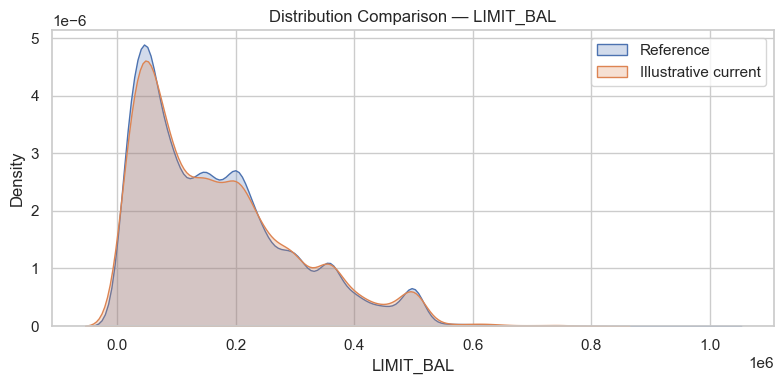

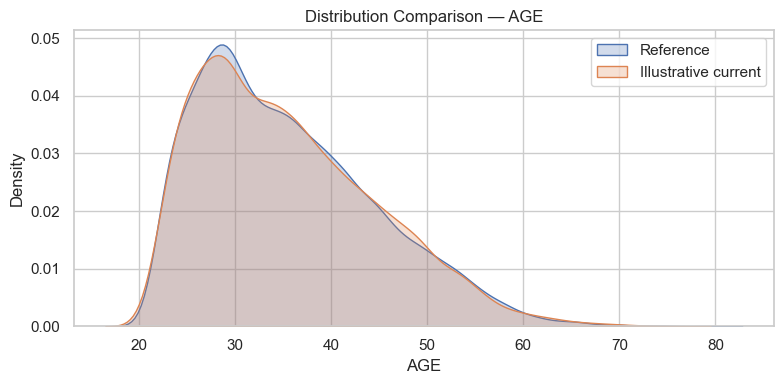

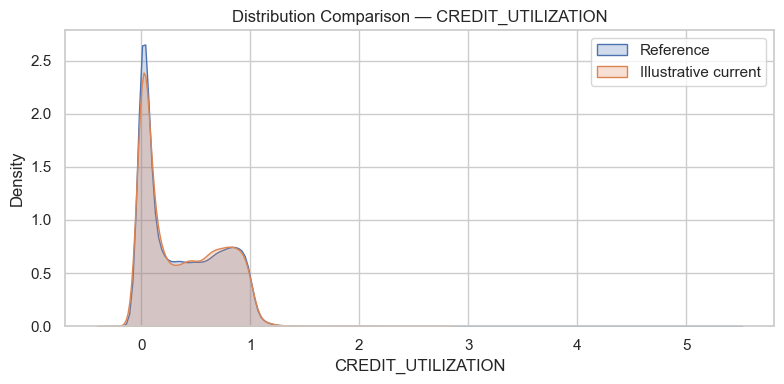

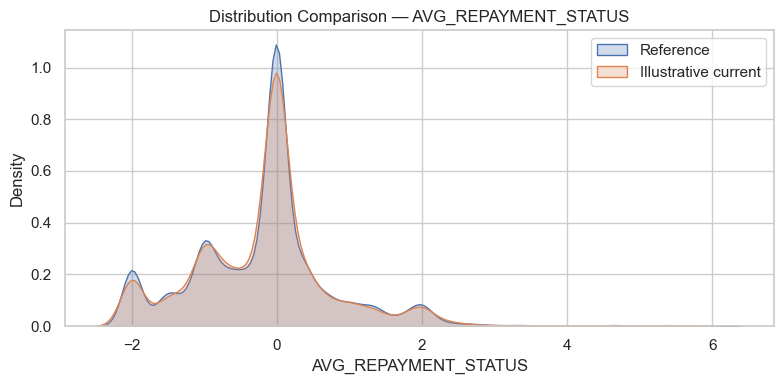

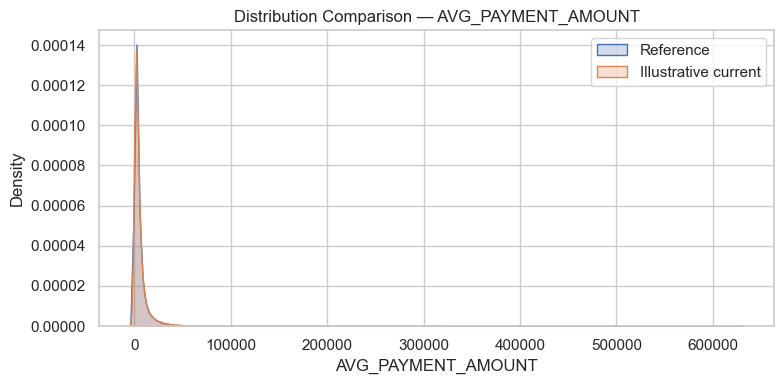

In [4]:
for feature in features_to_monitor:
    if feature in reference and feature in current:
        plt.figure(figsize=(8, 4))
        sns.kdeplot(reference[feature].dropna(), label="Reference", fill=True)
        sns.kdeplot(current[feature].dropna(), label="Illustrative current", fill=True)
        plt.title(f"Distribution Comparison — {feature}")
        plt.legend()
        plt.tight_layout()
        plt.savefig(PROJECT_ROOT / "reports" / f"psi_distribution_{feature}.png", dpi=180)
        plt.show()

## 4. PSI interpretation

Common rules of thumb are:
- PSI < 0.10: relatively small shift.
- 0.10 to < 0.25: moderate shift; investigate.
- ≥ 0.25: material shift; investigate urgently.

These are heuristics, not universal regulatory thresholds. PSI is sensitive to binning, sample size, and data quality. Monitoring should also include missingness, category mix, score distribution, observed default rate, calibration, and model performance when labels mature.